<a href="https://colab.research.google.com/github/wcliao1962/2025_DL/blob/master/%E5%86%92%E9%9A%AA15_16_%E7%94%A8_CNN_%E5%81%9A%E5%9C%96%E5%BD%A2%E8%BE%A8%E8%AD%98.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

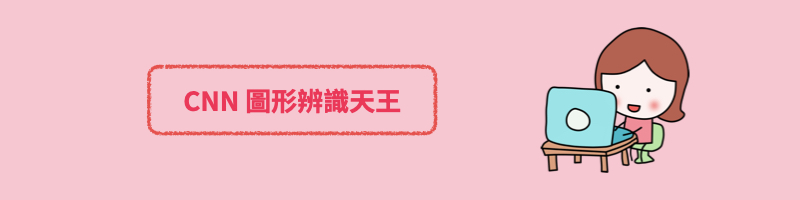

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import SGD, Adam

### 1. 讀入 CIFAR-10 數據集

CIFAR-10 是一個小尺吋（32x32）彩色圖片資料集，其中，訓練集包含了 50000 張大小為 32x32 的彩色圖片；測試集包含了 10000 張大小為 32x32 的彩色圖片。CIFAR-10 的圖片資料可分為以下 10 個種類：
* 飛機 (airplan)
* 交通工具 (automobile)
* 鳥 (bird)
* 貓 (cat)
* 鹿 (deer)
* 狗 (dog)
* 青蛙 (frog)
* 馬 (horse)
* 船 (ship)
* 卡車 (truck)

在這裡，我們將讓大家練習建構在 CIFAR-10 上的 CNN 分類模型


In [ ]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


### 2. 資料整理

#### 資料尺寸與通道數（Channel）

由於 CNN 模型的輸入資料必須是圖片，所以我們需要注意一張圖有多少個 channel。

因為CIFAR-10資料集的資料為彩色圖片，每一個像素點，其實包含了紅色（Red）、綠色（Green）以及藍色（Blue）三原色的強度，所以每一張圖有三個 channel，以及代表三種顏色的強度。

In [ ]:
x_train.shape

(50000, 32, 32, 3)

In [ ]:
np.unique(y_train)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [ ]:
print(f"資料的最小值: {np.min(x_train)}")
print(f"資料的最大值: {np.max(x_train)}")

資料的最小值: 0
資料的最大值: 255


In [ ]:
print(f"資料的最小值: {np.min(x_test)}")
print(f"資料的最大值: {np.max(x_test)}")

資料的最小值: 0
資料的最大值: 255


In [ ]:
x_train = x_train/255
x_test = x_test/255

In [ ]:
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [ ]:
y_train.shape

(50000, 10)

### 3. step 1: 打造函數學習機 (CNN)

In [ ]:
model = Sequential()

In [ ]:
model.add(Conv2D(16, (5, 5), padding='same',
                 input_shape=(32, 32, 3),
                 activation='relu'))

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │         1,216 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,216 (4.75 KB)

 Trainable params: 1,216 (4.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.add(MaxPool2D())

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,216 (4.75 KB)

 Trainable params: 1,216 (4.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.add(Conv2D(32, (5, 5), padding='same', activation='relu'))

In [ ]:
model.add(MaxPool2D())

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,048 (54.88 KB)

 Trainable params: 14,048 (54.88 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.add(Conv2D(64, (5, 5), padding='same', activation='relu'))
model.add(MaxPool2D())

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,312 (255.12 KB)

 Trainable params: 65,312 (255.12 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.add(Flatten())

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,312 (255.12 KB)

 Trainable params: 65,312 (255.12 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.add(Dense(32, activation='relu'))
model.add(Dense(10, activation='softmax'))

#### 看一下我們的神經網路

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        32,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 98,442 (384.54 KB)

 Trainable params: 98,442 (384.54 KB)

 Non-trainable params: 0 (0.00 B)

#### 組裝

In [ ]:
model.compile(loss='mse',
              optimizer=Adam(learning_rate=0.001),
              metrics=['accuracy'])

### 4. step 2: fit

In [ ]:
model.fit(x_train, y_train, batch_size=100, epochs=20)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 108s 211ms/step - accuracy: 0.2877 - loss: 0.0808
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 134s 195ms/step - accuracy: 0.5178 - loss: 0.0614
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 143s 197ms/step - accuracy: 0.5871 - loss: 0.0539
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 141s 195ms/step - accuracy: 0.6389 - loss: 0.0482
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 144s 199ms/step - accuracy: 0.6750 - loss: 0.0440
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 140s 194ms/step - accuracy: 0.7041 - loss: 0.0408
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 143s 197ms/step - accuracy: 0.7280 - loss: 0.0378
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 141s 195ms/step - accuracy: 0.7466 - loss: 0.0357
Epoch 9/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 143s 198ms/step - accuracy: 0.7690 - loss: 0.0325
Epoch 10/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 139s 193ms/step - accuracy: 0.7806 - loss: 0.0313
Epoch 11/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 144s 196ms/step - accuracy: 0.7891 - loss: 0.0299
Epoch 12

### 5. Step 3: 預測

In [ ]:
x_test[5].shape

(32, 32, 3)

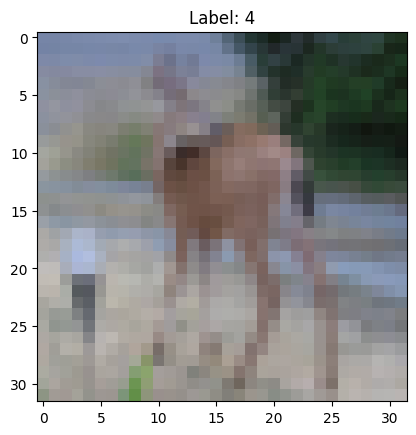

In [ ]:
plt.imshow(x_test[100])
plt.title(f"Label: {y_test[100].argmax()}");

In [ ]:
inp = x_test[5].reshape(1, 32, 32, 3)

In [ ]:
# inp= x_test[5:10]

In [ ]:
inp.shape

(5, 32, 32, 3)

In [ ]:
model.predict(inp)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 597ms/step


array([[7.9702504e-04, 9.2602434e-04, 1.8181825e-03, 1.4256327e-02,
        1.7195296e-02, 7.2392724e-03, 9.4955474e-01, 7.7219019e-03,
        3.4017605e-06, 4.8784140e-04],
       [4.9209787e-04, 6.8324804e-01, 8.1612092e-07, 9.6681790e-04,
        2.8897444e-09, 2.7625374e-03, 6.1727245e-05, 2.6581494e-05,
        1.4422649e-08, 3.1244138e-01],
       [6.1450229e-04, 1.7327230e-04, 5.7983962e-03, 3.8950366e-03,
        4.6479809e-03, 9.3299015e-05, 9.8416901e-01, 3.1416534e-05,
        1.5128004e-04, 4.2578703e-04],
       [1.5700226e-04, 1.0909039e-06, 4.1413054e-04, 9.5565307e-01,
        1.4907336e-02, 2.6503403e-02, 5.4071506e-04, 1.0343291e-03,
        7.5964647e-04, 2.9246088e-05],
       [5.8745918e-05, 9.9721307e-01, 8.0350907e-07, 2.1511477e-07,
        2.6658281e-10, 6.3211223e-07, 4.0599229e-05, 1.1363917e-07,
        3.9610306e-08, 2.6857406e-03]], dtype=float32)

In [ ]:
np.argmax(model.predict(inp), axis=-1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


array([6, 1, 6, 3, 1])

In [ ]:
y_predict = np.argmax(model.predict(x_test), axis=-1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [ ]:
n = 100

print('神經網路預測是:', y_predict[n])
plt.imshow(x_test[n], cmap='Greys');

NameError: name 'y_predict' is not defined

In [ ]:
score = model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6952 - loss: 0.0448


In [ ]:
score

[0.04533564671874046, 0.6938999891281128]

In [ ]:
print(f"loss: {score[0]}")
print(f"正確率: {score[1]*100:.2f}%")

loss: 0.04533564671874046
正確率: 69.39%


### 6. 更酷炫的互動呈現

我們先來準備標籤資料的中英文對照

In [ ]:
from ipywidgets import interact_manual

In [ ]:
class_name = ['飛機', '汽車', '鳥', '貓', '鹿', '狗', '青蛙', '馬', '船', '卡車']

In [ ]:
def test(測試編號):
    plt.imshow(x_test[測試編號], cmap='Greys')
    print('神經網路判斷為:', class_name[y_predict[測試編號]])

In [ ]:
interact_manual(test, 測試編號=(0, 9999));

interactive(children=(IntSlider(value=4999, description='測試編號', max=9999), Button(description='Run Interact', …

到底測試資料整體的表現如何呢？我們可以給神經網路「總評量」。

In [ ]:
score = model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6952 - loss: 0.0448


In [ ]:
score

[0.04533564671874046, 0.6938999891281128]

In [ ]:
print(f"loss: {score[0]}")
print(f" 正確率 : {score[1]*100:.2f}%")

loss: 0.04533564671874046
 正確率 : 69.39%
